## Validation par blocs géographiques

Ce notebook exécute l'étude préenregistrée dans `docs/research_spatial_blocks.md`, issue de la revue du projet par une mentore experte. La validation croisée du protocole tient à l'écart des régions de niveau 1, mais une région tenue à l'écart peut ressembler à sa voisine présente à l'entraînement. L'étude mesure de combien l'erreur du modèle retenu de `regional` augmente lorsque les régions évaluées sont éloignées de toute région d'entraînement.

**Précautions**

- Seul le développement est utilisé, et les ensembles de test ne sont pas consultés.
- Le modèle retenu est employé tel qu'il a été choisi, avec ses variables, ses paramètres et ses 2 000 arbres.
- La référence hiérarchique est recalculée dans chaque schéma, sur les mêmes lignes d'entraînement.

**Préalable**

Les schémas S1, S2 et S3 sont calculés par `python -m src.recherche.validation_spatiale`, en une vingtaine de minutes. Le schéma S0 reprend les prédictions de `10_modeling.ipynb`. Le notebook relit ces prédictions et s'exécute en une minute environ.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.models.bilan import intervalle_bootstrap
from src.recherche.validation_spatiale import (
    NOMBRE_BLOCS, SCHEMAS, bilan, blocs_geographiques, decoupages, developpement_regional, erreurs, lire_schema, zones,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
developpement = developpement_regional()
table_zones = zones(developpement)
blocs = blocs_geographiques(table_zones)
bloc_ligne = developpement["GDAM_ID"].map(blocs)
schemas = {s: lire_schema(s, developpement) for s in SCHEMAS}

### 1. Tests unitaires

Les tests de l'étude vérifient la distance de grand cercle, la stabilité des blocs, le découpage par pays et le respect de la zone tampon.

In [2]:
execution = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
    cwd=RACINE, capture_output=True, text=True,
)
print(execution.stderr.strip().splitlines()[-3:])

['Ran 111 tests in 7.054s', '', 'OK']


### 2. Blocs et découpages

Les 1 258 zones du développement sont regroupées en huit blocs par la méthode des k-moyennes sur leurs coordonnées à la surface du globe. La distance d'une ligne évaluée à l'entraînement est la distance entre le centroïde de sa zone et celui de la zone d'entraînement la plus proche.

In [3]:
composition = developpement.groupby(bloc_ligne).agg(lignes=("country", "size"), zones=("GDAM_ID", "nunique"),
                                                    pays=("country", "nunique"))
composition["principaux_pays"] = developpement.groupby(bloc_ligne)["country"].agg(lambda s: ", ".join(s.value_counts().index[:4]))
display(composition)
for schema in ["S1", "S2", "S3"]:
    decoupes = decoupages(developpement, schema)
    print(schema, ":", len(decoupes), "découpages | chevauchement :", any((a & e).any() for a, e in decoupes),
          "| lignes évaluées :", int(sum(e.sum() for _, e in decoupes)),
          "| lignes d'entraînement en moyenne :", int(np.mean([a.sum() for a, _ in decoupes])))
    distance = schemas[schema]["distance_km"]
    print("   distance à la zone d'entraînement la plus proche, médiane", round(distance.median()), "km, minimum",
          round(distance.min()), "km")

,lignes,zones,pays,principaux_pays
GDAM_ID,,,,
0,7435,162,9,"Senegal, Mali, Mauritania, Guinea"
1,11193,128,6,"Ethiopia, Somalia, Sudan, Kenya"
2,10968,131,9,"Cameroon, Chad, Nigeria, Angola"
3,445,27,2,"Sudan, Egypt"
4,24974,272,13,"Zambia, Malawi, Madagascar, Mozambique"
5,832,91,3,"Algeria, Morocco, Tunisia"
6,33992,283,8,"Benin, Burkina Faso, Niger, Nigeria"
7,13236,164,10,"Uganda, Kenya, Tanzania, Rwanda"


S1 : 45 découpages | chevauchement : False | lignes évaluées : 103075 | lignes d'entraînement en moyenne : 100784
   distance à la zone d'entraînement la plus proche, médiane 181 km, minimum 11 km


S2 : 8 découpages | chevauchement : False | lignes évaluées : 103075 | lignes d'entraînement en moyenne : 90190
   distance à la zone d'entraînement la plus proche, médiane 595 km, minimum 77 km


S3 : 8 découpages | chevauchement : False | lignes évaluées : 103075 | lignes d'entraînement en moyenne : 88829
   distance à la zone d'entraînement la plus proche, médiane 747 km, minimum 251 km


**Constat**

- Les huit blocs correspondent à de grandes régions, comme l'Afrique de l'Ouest côtière, la Corne de l'Afrique, la vallée du Nil, le Maghreb, l'Afrique australe et les Grands Lacs. Ils comptent de 445 à 33 992 lignes.
- Aucune ligne n'est à la fois entraînée et évaluée, et chaque ligne est évaluée une fois.
- La zone d'entraînement la plus proche est à 181 km en médiane lorsqu'un pays est tenu à l'écart, à 595 km pour les blocs et à 747 km pour les blocs entourés d'une zone tampon, jamais à moins de 251 km dans ce dernier cas.

### 3. Erreur et compétence par schéma

L'écart à S0 est accompagné d'un intervalle de confiance à 95 % obtenu par bootstrap des pays. Le second tableau donne le gain du modèle sur la référence, avec son intervalle.

In [4]:
resultats = bilan(developpement)
display(resultats.round(4))
gains = []
for schema in SCHEMAS:
    modele, reference = erreurs(developpement, schemas[schema])
    bas, haut = intervalle_bootstrap(reference - modele, developpement["country"])
    gains.append({"schema": schema, "gain_sur_reference": (reference - modele).mean(), "ic_bas": bas, "ic_haut": haut})
display(pd.DataFrame(gains).round(4))

,schema,lignes,mae_log,mae_log_reference,competence,ecart_a_S0,ic_bas,ic_haut
0,S0,103075,0.3579,0.4166,0.1409,0.0000,0.0000,0.0000
1,S1,103075,0.5452,0.5526,0.0133,0.1874,0.1466,0.2357
2,S2,103075,0.5038,0.5187,0.0288,0.1459,0.1005,0.1981
3,S3,103075,0.5371,0.5440,0.0127,0.1792,0.1352,0.2238


,schema,gain_sur_reference,ic_bas,ic_haut
0,S0,0.0587,0.0436,0.0741
1,S1,0.0073,-0.0213,0.0399
2,S2,0.0149,-0.0072,0.0399
3,S3,0.0069,-0.0135,0.0336


**Constat**

- L'erreur du modèle passe de 0,358 dans la validation du protocole à 0,545 lorsqu'un pays est tenu à l'écart, 0,504 pour les blocs et 0,537 pour les blocs avec zone tampon. Les hausses vont de 0,146 à 0,187, toutes significatives.
- La compétence tombe de 14,1 % à 1,3 %, 2,9 % et 1,3 %. Le gain sur la référence, net dans la validation du protocole avec un intervalle de 0,044 à 0,074, n'est plus significatif dans les trois autres schémas, dont les intervalles contiennent zéro.
- L'erreur est plus forte lorsqu'un pays est tenu à l'écart que pour les blocs, alors que la zone d'entraînement la plus proche y est trois fois plus proche.

**Analyse**

- La validation du protocole surestime nettement la capacité du modèle à prédire une région éloignée. Son avantage sur la référence repose surtout sur ce qu'il apprend des régions voisines et du pays lui-même, et non sur des relations entre rendement, climat, sol et relief qui se transposeraient d'une région du continent à une autre.
- La perte de l'effet propre au pays coûte davantage que la distance. Le pays porte à la fois des conditions agricoles et des façons de produire les statistiques, que les variables explicatives ne décrivent pas.

### 4. Erreur selon la distance

Dans le schéma des blocs, l'erreur du modèle et de la référence est ventilée par classe de distance à la zone d'entraînement la plus proche.

,lignes,modele,reference,competence
classe,,,,
"(0, 250]",10781,0.390,0.437,0.108
"(250, 500]",27161,0.487,0.528,0.077
"(500, 750]",34383,0.510,0.513,0.004
"(750, 1000]",18946,0.512,0.529,0.033
"(1000, 1500]",6448,0.528,0.526,-0.003
"(1500, 4000]",5356,0.719,0.633,-0.137


Corrélation de rang entre distance et erreur absolue dans S2 : 0.109


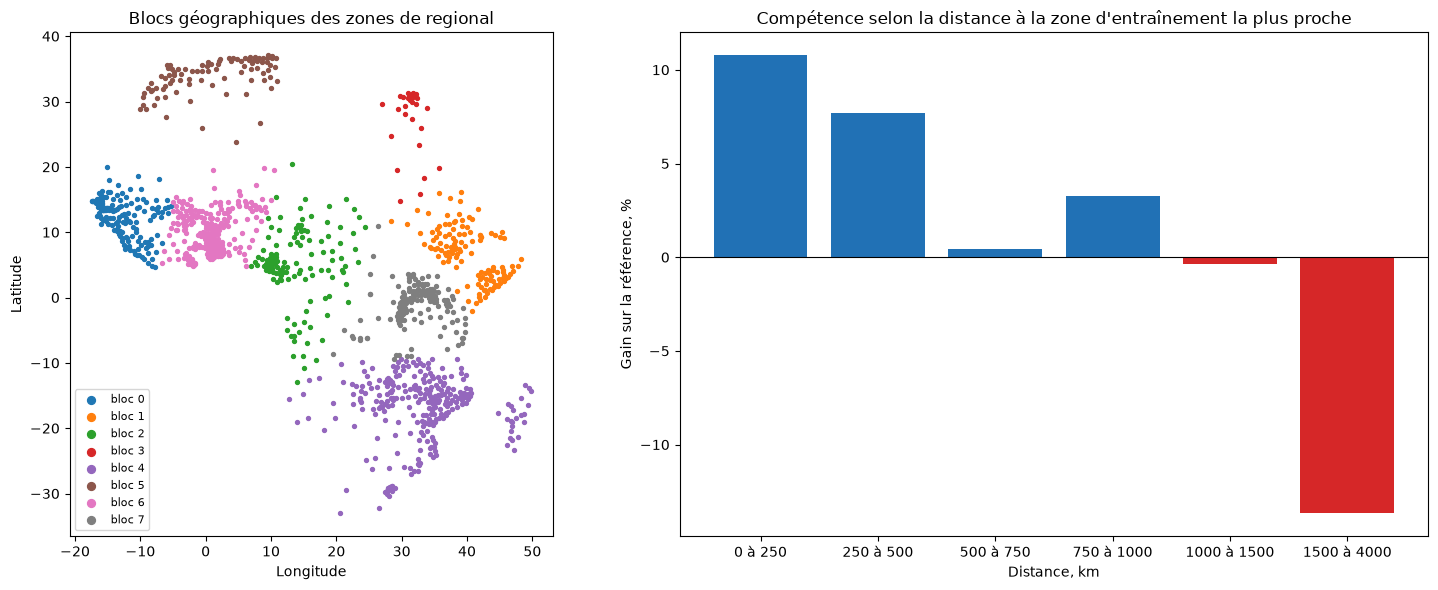

In [5]:
modele, reference = erreurs(developpement, schemas["S2"])
classes = pd.cut(schemas["S2"]["distance_km"], [0, 250, 500, 750, 1000, 1500, 4000])
par_distance = (pd.DataFrame({"modele": modele, "reference": reference, "classe": classes})
                .groupby("classe", observed=True)
                .agg(lignes=("modele", "size"), modele=("modele", "mean"), reference=("reference", "mean")))
par_distance["competence"] = 1 - par_distance["modele"] / par_distance["reference"]
display(par_distance.round(3))
correlation = schemas["S2"]["distance_km"].rank().corr(modele.rank())
print("Corrélation de rang entre distance et erreur absolue dans S2 :", round(correlation, 3))

figure, (carte, courbe) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.2]})
for bloc in range(NOMBRE_BLOCS):
    membres = table_zones[blocs == bloc]
    carte.scatter(membres["longitude"], membres["latitude"], s=8, label=f"bloc {bloc}")
carte.set_title("Blocs géographiques des zones de regional")
carte.set_xlabel("Longitude")
carte.set_ylabel("Latitude")
carte.set_aspect("equal")
carte.legend(fontsize=8, markerscale=2, loc="lower left")
etiquettes = [f"{int(c.left)} à {int(c.right)}" for c in par_distance.index]
couleurs = np.where(par_distance["competence"] >= 0, "#2171b5", "#d62728")
courbe.bar(etiquettes, par_distance["competence"] * 100, color=couleurs)
courbe.axhline(0, color="black", lw=0.8)
courbe.set_title("Compétence selon la distance à la zone d'entraînement la plus proche")
courbe.set_xlabel("Distance, km")
courbe.set_ylabel("Gain sur la référence, %")
plt.tight_layout()
plt.savefig(RACINE / "reports" / "figures" / "blocs_geographiques.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

**Constat**

- La compétence vaut 10,8 % à moins de 250 km, 7,7 % de 250 à 500 km, puis moins de 4 % de 500 à 1 000 km. Elle devient négative au-delà de 1 000 km, et atteint -13,7 % au-delà de 1 500 km.
- La corrélation de rang entre distance et erreur absolue vaut 0,109.

**Analyse**

L'utilité du modèle décroît avec l'éloignement des données d'entraînement. Au-delà d'environ 500 km, il n'apporte presque plus rien par rapport aux moyennes de la culture, et au-delà de 1 000 km il fait moins bien qu'elles.

### 5. Verdict des hypothèses

Les verdicts suivent les énoncés de la section 6 du plan.

In [6]:
s0, s2, s3 = (erreurs(developpement, schemas[s])[0] for s in ["S0", "S2", "S3"])
competences = resultats.set_index("schema").loc[["S1", "S2", "S3"], "competence"]
verdicts = pd.DataFrame([
    {"hypothese": "H1", "mesure": (s2 - s0).mean(), "confirmee": (s2 - s0).mean() >= 0.02},
    {"hypothese": "H2", "mesure": competences.min(), "confirmee": bool((competences > 0).all())},
    {"hypothese": "H3", "mesure": correlation, "confirmee": correlation > 0},
    {"hypothese": "H4", "mesure": (s3 - s2).mean(), "confirmee": (s3 - s2).mean() > 0},
])
display(verdicts.round(4))

,hypothese,mesure,confirmee
0,H1,0.1459,True
1,H2,0.0127,True
2,H3,0.1092,True
3,H4,0.0333,True


**Constat**

- **H1 est confirmée.** L'erreur augmente de 0,146 en passant de S0 à S2, bien au-delà du seuil de 0,02.
- **H2 est confirmée au sens strict de son énoncé**, puisque la compétence reste positive dans S1, S2 et S3, de 1,3 à 2,9 %. Ces gains ne sont cependant pas significatifs, et l'énoncé, qui ne demandait pas de significativité, était trop peu exigeant.
- **H3 est confirmée**, avec une corrélation de rang de 0,109 entre distance et erreur.
- **H4 est confirmée.** La zone tampon augmente l'erreur de 0,033 par rapport aux blocs sans zone tampon.

### 6. Blocs et pays

L'erreur est ventilée par bloc, puis par pays lorsque chaque pays est tenu à l'écart à son tour.

In [7]:
par_bloc = pd.DataFrame({s: erreurs(developpement, schemas[s])[0] for s in ["S0", "S2", "S3"]}).groupby(bloc_ligne).mean()
par_bloc["reference_S2"] = erreurs(developpement, schemas["S2"])[1].groupby(bloc_ligne).mean()
par_bloc["principaux_pays"] = composition["principaux_pays"]
display(par_bloc.round(3))
modele, reference = erreurs(developpement, schemas["S1"])
s0 = erreurs(developpement, schemas["S0"])[0]
par_pays = pd.DataFrame({"S1": modele, "S0": s0, "reference_S1": reference, "pays": developpement["country"]}).groupby("pays").agg(
    lignes=("S1", "size"), S0=("S0", "mean"), S1=("S1", "mean"), reference_S1=("reference_S1", "mean"))
par_pays["competence_S1"] = 1 - par_pays["S1"] / par_pays["reference_S1"]
print("Pays où le modèle fait moins bien que la référence lorsqu'il est tenu à l'écart :",
      int((par_pays["competence_S1"] < 0).sum()), "sur", len(par_pays))
display(par_pays.sort_values("competence_S1").round(3).head(10))

,S0,S2,S3,reference_S2,principaux_pays
GDAM_ID,,,,,
0,0.394,0.471,0.463,0.494,"Senegal, Mali, Mauritania, Guinea"
1,0.343,0.640,0.636,0.668,"Ethiopia, Somalia, Sudan, Kenya"
2,0.370,0.446,0.463,0.458,"Cameroon, Chad, Nigeria, Angola"
3,0.464,1.040,1.040,0.959,"Sudan, Egypt"
4,0.381,0.536,0.592,0.556,"Zambia, Malawi, Madagascar, Mozambique"
5,0.387,0.566,0.566,0.554,"Algeria, Morocco, Tunisia"
6,0.342,0.470,0.505,0.474,"Benin, Burkina Faso, Niger, Nigeria"
7,0.333,0.460,0.517,0.483,"Uganda, Kenya, Tanzania, Rwanda"


Pays où le modèle fait moins bien que la référence lorsqu'il est tenu à l'écart : 18 sur 45


,lignes,S0,S1,reference_S1,competence_S1
pays,,,,,
South Africa,1138,0.383,1.477,0.957,-0.544
Egypt,152,0.300,2.035,1.375,-0.480
Madagascar,3010,0.310,0.559,0.429,-0.303
Tunisia,244,0.404,0.708,0.576,-0.229
Ghana,987,0.381,0.610,0.500,-0.220
Algeria,320,0.297,0.550,0.471,-0.168
Malawi,5150,0.276,0.551,0.505,-0.091
Republic of the Congo,25,0.323,0.503,0.465,-0.082
Benin,11495,0.295,0.451,0.419,-0.077


**Constat**

- Le bloc de la vallée du Nil, réunissant l'Égypte et le nord du Soudan, est le plus difficile, avec une erreur de 1,040 contre 0,464 dans la validation du protocole. La Corne de l'Afrique passe de 0,343 à 0,640.
- Lorsqu'il est tenu à l'écart, le modèle fait moins bien que la référence dans 18 pays sur 45, notamment en Afrique du Sud, de 54 %, en Égypte, de 48 %, et à Madagascar, de 30 %.

**Analyse**

Les pays les plus mal prédits ont vraisemblablement des systèmes agricoles sans équivalent chez leurs voisins, comme l'agriculture commerciale sud-africaine, l'agriculture irriguée de la vallée du Nil ou l'insularité malgache. Le modèle ne peut pas les déduire des autres pays.

### 7. Synthèse

**Résultats**

| Schéma | Erreur du modèle | Erreur de la référence | Compétence | Gain significatif |
|---|---:|---:|---:|---|
| Validation du protocole | 0,358 | 0,417 | 14,1 % | Oui |
| Un pays tenu à l'écart | 0,545 | 0,553 | 1,3 % | Non |
| Blocs géographiques | 0,504 | 0,519 | 2,9 % | Non |
| Blocs et zone tampon | 0,537 | 0,544 | 1,3 % | Non |

**Conséquences pour l'usage du modèle**

- Les scores spatiaux du projet valent pour des régions proches des données d'entraînement, à quelques centaines de kilomètres au plus. Ils ne valent pas pour une région éloignée ni pour un pays absent de la base.
- Pour un pays absent de la base, le modèle n'est pas meilleur que la moyenne de la culture.

**Limites**

- Le nombre de blocs et le rayon de la zone tampon ont été fixés a priori, et d'autres choix donneraient des écarts différents.
- L'effet de l'éloignement et celui de l'absence d'effet pays appris restent mêlés.
- Le modèle n'a pas été conçu pour l'extrapolation lointaine. Un modèle sans variable de pays, ou fondé sur des zones agroécologiques, pourrait mieux se transposer, ce que l'étude ne teste pas.